# Stage 6: final frozen held-out test evaluation

All six preselected checkpoints: CNN and GRU, seeds42/43/44. Frozen protocol, source, checkpoint, split and label hashes are verified before any forward pass. No retraining, tuning, masking, threshold changes or seed selection. Evaluation mode and inference_mode are used. Test metrics are final descriptive analysis only.

Report each seed, plus arithmetic mean and sample SD (ddof=1). Repeated predictions of the same 2,141 tweets are not independent examples. Small example sample is fixed before scoring: seed42 only, one correct and one incorrect example per true class per model, selected by smallest SHA256(2026|model|source_row). No keyword search or post-result sample replacement.

See STAGE6.md for final working findings and marking-scheme checklist. This notebook is not the assignment report.

In [1]:
from pathlib import Path
import sys
ROOT=Path.cwd().resolve()
if not (ROOT/'src/stage6.py').exists(): ROOT=ROOT.parent
assert Path(sys.prefix).resolve()==(ROOT/'.venv').resolve()
sys.path.insert(0,str(ROOT/'src'))
from stage6 import run
summary=run()
assert summary['all_saved_metrics_verified'] and summary['previous_artifacts_preserved']

cnn_seed42 test accuracy 0.7580569827183559 macro-F1 0.7064145131537233


cnn_seed43 test accuracy 0.7669313404950957 macro-F1 0.7122209681464761


cnn_seed44 test accuracy 0.7692666978047641 macro-F1 0.7078911177760173


gru_seed42 test accuracy 0.760859411489958 macro-F1 0.6945142505846934


gru_seed43 test accuracy 0.7426436244745446 macro-F1 0.6916940179431877


gru_seed44 test accuracy 0.7585240541802896 macro-F1 0.7026852333919654


In [2]:
import pandas as pd
from IPython.display import display, Image
display(pd.read_csv(ROOT/'results/stage6/checkpoint_comparison.csv'))
display(pd.read_csv(ROOT/'results/stage6/model_summary.csv'))
display(pd.read_csv(ROOT/'results/stage6/per_class_metrics.csv'))
print('Evaluation wall seconds before plots:',summary['evaluation_wall_seconds_before_plots'])

,model,seed,accuracy,macro_f1,weighted_f1,evaluation_seconds
0,cnn,42,0.758057,0.706415,0.765318,0.207941
1,cnn,43,0.766931,0.712221,0.769995,0.164031
2,cnn,44,0.769267,0.707891,0.770703,0.165914
3,gru,42,0.760859,0.694514,0.763662,0.311922
4,gru,43,0.742644,0.691694,0.751079,0.279343
5,gru,44,0.758524,0.702685,0.763269,0.173519


,model,accuracy_mean,accuracy_sample_std,macro_f1_mean,macro_f1_sample_std,weighted_f1_mean,weighted_f1_sample_std
0,cnn,0.764752,0.005914,0.708842,0.003018,0.768672,0.002926
1,gru,0.754009,0.009912,0.696298,0.005709,0.759337,0.007154


,model,seed,class,precision,recall,f1-score,support
0,cnn,42,negative,0.887980,0.797943,0.840557,1361.0
1,cnn,42,neutral,0.541071,0.679372,0.602386,446.0
2,cnn,42,positive,0.653631,0.700599,0.676301,334.0
3,cnn,43,negative,0.865844,0.825129,0.844996,1361.0
4,cnn,43,neutral,0.576763,0.623318,0.599138,446.0
5,cnn,43,positive,0.665746,0.721557,0.692529,334.0
6,cnn,44,negative,0.859925,0.843497,0.851632,1361.0
7,cnn,44,neutral,0.578495,0.603139,0.590560,446.0
8,cnn,44,positive,0.674487,0.688623,0.681481,334.0
9,gru,42,negative,0.864536,0.834680,0.849346,1361.0


Evaluation wall seconds before plots: 3.292751600005431


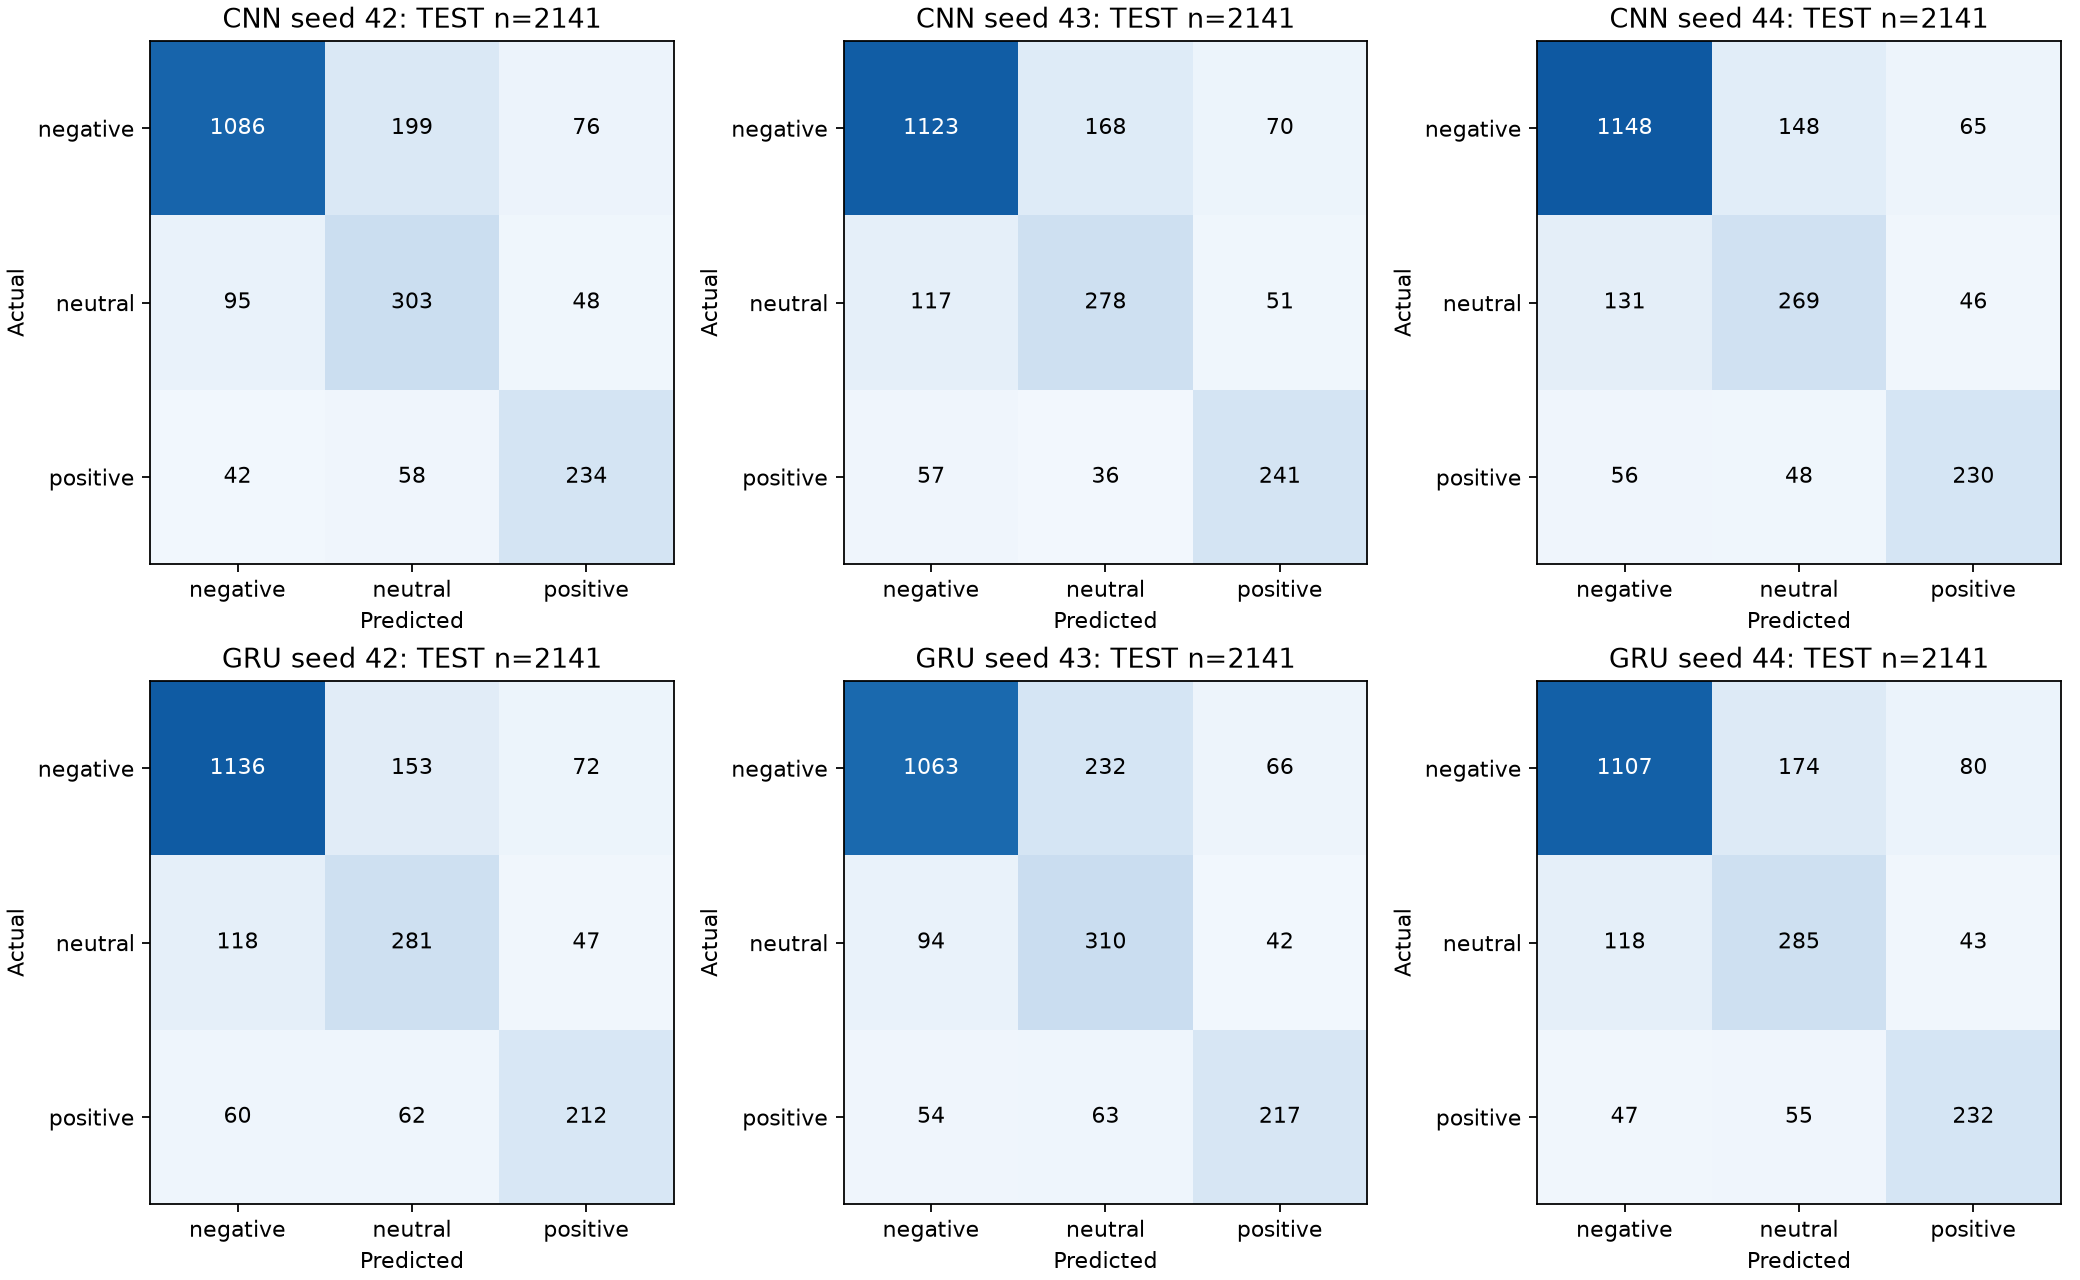

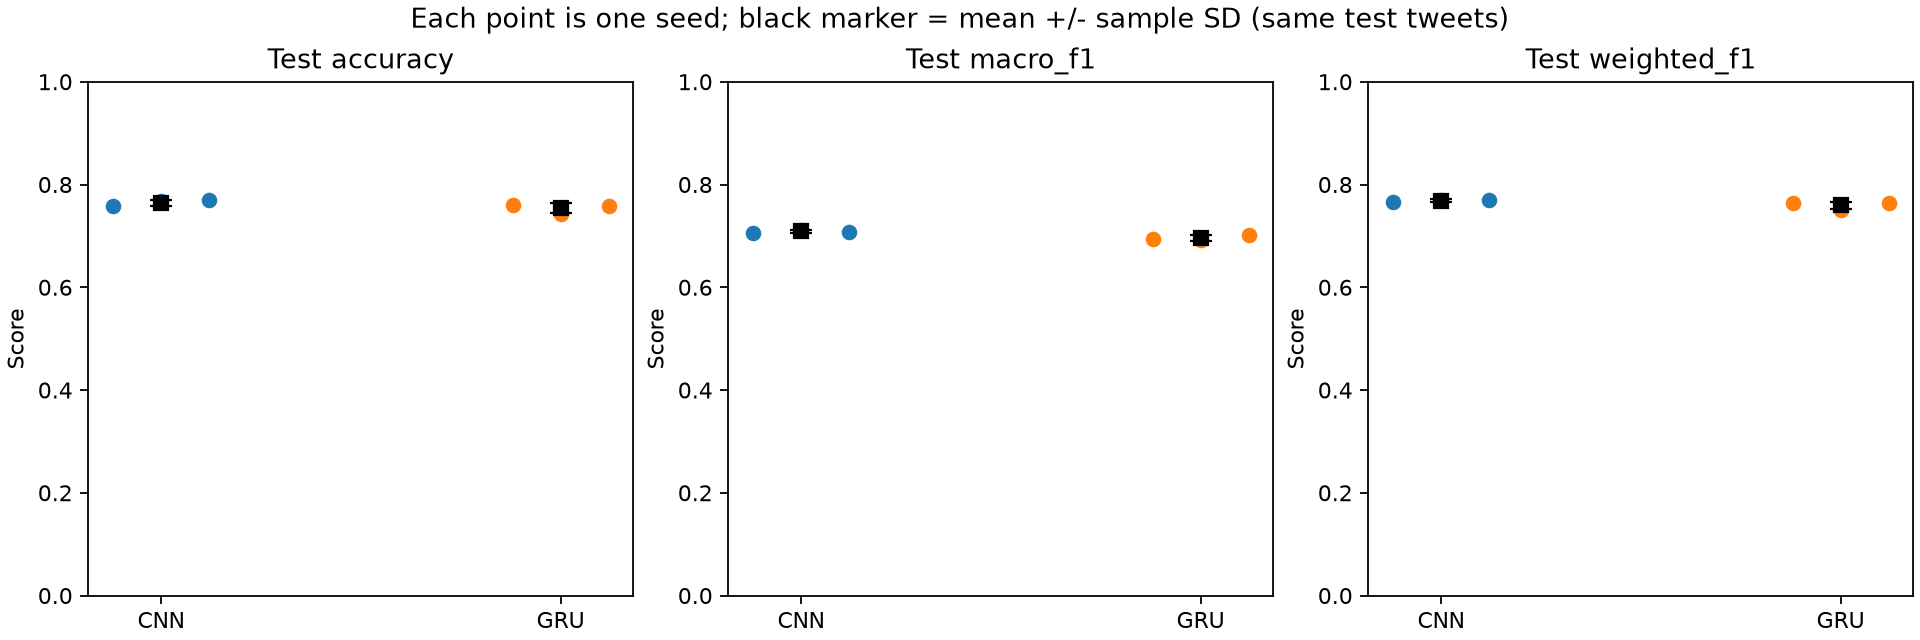

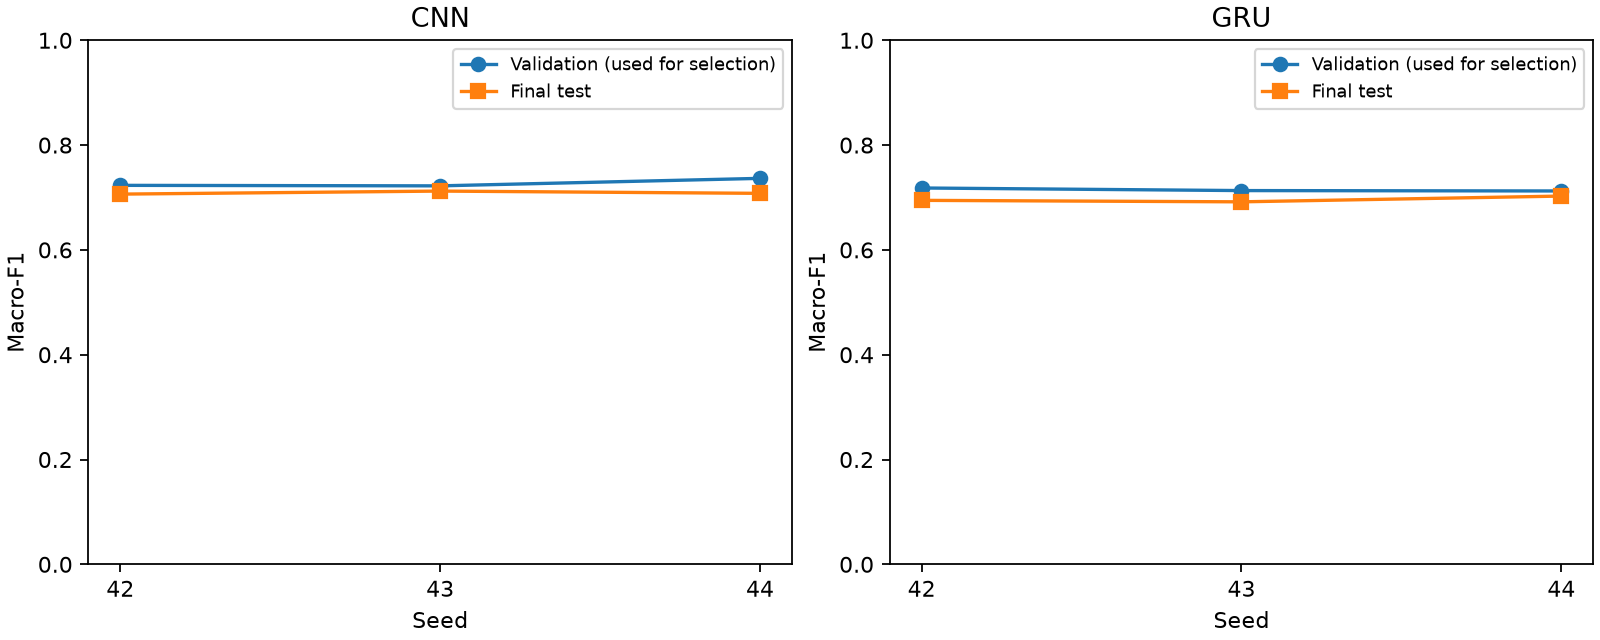

,model,source_row,true_label,predicted_label,correct,text,unseen_tokens_json
0,cnn,3522,negative,negative,True,@united 8h flight without a working screen for...,"[""#unitedfails"", ""#worsttripofmylife""]"
1,cnn,635,negative,positive,False,@united This isn't a one time thing either! It...,"[""pattern"", ""repeated""]"
2,cnn,2842,neutral,neutral,True,@united Old school ride home to LAX from Houst...,"[""Old"", ""#flyingRetro""]"
3,cnn,12211,neutral,positive,False,@AmericanAir hook me up with a free trip to Ba...,"[""Barbados"", ""beaches""]"
4,cnn,5664,positive,positive,True,@SouthwestAir that's awesome! Love flying SWA!,[]
5,cnn,1316,positive,negative,False,@united have Michelle at T1 ORD train your oth...,"[""Michelle"", ""T1""]"
6,gru,6731,negative,negative,True,@SouthwestAir been on hold for &gt;30 minutes ...,[]
7,gru,5803,negative,neutral,False,"@SouthwestAir, what do you know? Finally lined...",[]
8,gru,8038,neutral,neutral,True,@JetBlue and @WSJ team up offering in-flight a...,"[""journal""]"
9,gru,3468,neutral,negative,False,@united - who can eat at an airport for $7? #a...,"[""#areyounew"", ""#no800number"", ""#feeltheheat""]"


Final evaluation complete. No model choices changed after test access.


In [3]:
display(Image(filename=str(ROOT/'results/stage6/test_confusion_matrices.png')))
display(Image(filename=str(ROOT/'results/stage6/test_model_comparison.png')))
display(Image(filename=str(ROOT/'results/stage6/validation_test_comparison.png')))
sample=pd.read_csv(ROOT/'results/stage6/example_sample.csv',dtype={'source_row':str,'tweet_id':str})
display(sample[['model','source_row','true_label','predicted_label','correct','text','unseen_tokens_json']])
print('Final evaluation complete. No model choices changed after test access.')

Metric CSV/JSON files and per-checkpoint prediction CSV/NPZ files provide traceability to source rows, original tweet IDs, true labels, probabilities and logits. Every matrix is seed-specific. Sample examples are illustrative, not a representative error-rate study. Human interpretations and remaining assignment work are in STAGE6.md. Codex generated and executed final evaluation code and working analysis; no assignment report or AI acknowledgement is written.